# Breast Cancer Classification

## Objective
This project compares five machine learning classification algorithms using the
Breast Cancer Wisconsin (Diagnostic) dataset:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

The models predict whether a tumor is benign or malignant. We will inspect and
preprocess the dataset, split it into training and testing sets, and compare the
models using Accuracy, AUC, Precision, Recall, F1, and MCC.

This is an educational project and is not a medical diagnostic tool.

In [10]:
!pip -q install scikit-learn pandas numpy matplotlib seaborn joblib

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

sns.set_theme(style="whitegrid")


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Dataset

This notebook uses the Breast Cancer Wisconsin (Diagnostic) dataset from the
UCI Machine Learning Repository. It contains 569 rows and 30 numeric features.
The target is the diagnosis: benign or malignant.

Scikit-learn provides a copy of this dataset, so it can be loaded directly.

In [2]:
dataset = load_breast_cancer(as_frame=True)

# The source labels are encoded as 0 = malignant and 1 = benign.
df = dataset.data.copy()
df["diagnosis"] = dataset.target.map({
    0: "malignant",
    1: "benign"
})

target_column = "diagnosis"
feature_columns = [column for column in df.columns if column != target_column]

print(f"Rows: {df.shape[0]}")
print(f"Input features: {len(feature_columns)}")
print(f"Target column: {target_column}")

assert df.shape[0] >= 500, "The dataset must contain at least 500 rows."
assert len(feature_columns) >= 12, "The dataset must contain at least 12 input features."

display(df.head())

Rows: 569
Input features: 30
Target column: diagnosis


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


## Basic EDA

Exploratory Data Analysis (EDA) helps us understand the data before training.
We will check column types, missing values, summary statistics, class balance,
and the distributions of a few sample features.

In [3]:
print("Dataset shape:", df.shape)
print("\nData types:")
display(df.dtypes.value_counts())

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("missing values"))

print("\nSummary statistics for selected features:")
display(df[feature_columns[:6]].describe().round(2))

print("\nDiagnosis counts:")
display(df[target_column].value_counts().to_frame("count"))

Dataset shape: (569, 31)

Data types:


float64    30
str         1
Name: count, dtype: int64


Missing values per column:


,missing values
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0



Summary statistics for selected features:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
count,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10
std,3.52,4.30,24.30,351.91,0.01,0.05
min,6.98,9.71,43.79,143.50,0.05,0.02
25%,11.70,16.17,75.17,420.30,0.09,0.06
50%,13.37,18.84,86.24,551.10,0.10,0.09
75%,15.78,21.80,104.10,782.70,0.11,0.13
max,28.11,39.28,188.50,2501.00,0.16,0.35



Diagnosis counts:


,count
diagnosis,
benign,357
malignant,212


The first chart shows how many examples belong to each diagnosis class.
The second chart compares one measurement across the two classes. These plots
help us see whether the classes have similar sample counts and whether a
feature's values appear different between classes.

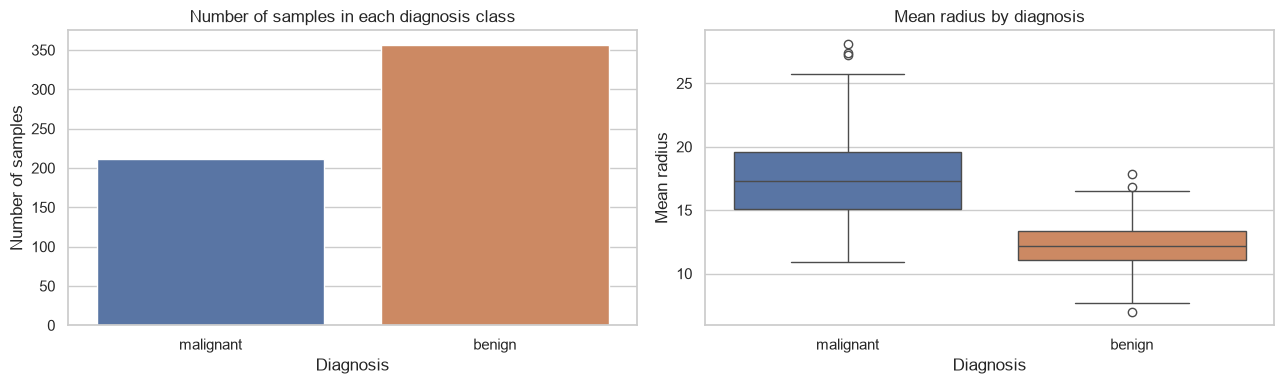

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(
    data=df,
    x=target_column,
    hue=target_column,
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Number of samples in each diagnosis class")
axes[0].set_xlabel("Diagnosis")
axes[0].set_ylabel("Number of samples")

sns.boxplot(
    data=df,
    x=target_column,
    y="mean radius",
    hue=target_column,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Mean radius by diagnosis")
axes[1].set_xlabel("Diagnosis")
axes[1].set_ylabel("Mean radius")

plt.tight_layout()
plt.show()

## Preprocessing

The target is separated from the input features. The diagnosis labels are
encoded as numbers for model training. We split the dataset into training and
testing portions; the test data is held back for evaluation.

Stratification keeps the class proportions similar in both portions. A fixed
random state makes the split reproducible.

In [5]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

X = df[feature_columns].copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[target_column])

print("Numeric label mapping:")
for number, label in enumerate(label_encoder.classes_):
    print(f"{number} = {label}")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Test data:", X_test.shape)

Numeric label mapping:
0 = benign
1 = malignant

Training data: (426, 30)
Test data: (143, 30)


## Model training and evaluation

This cell trains all five classifiers in sequence using the same training data,
then evaluates each one on the same test data.

Logistic Regression, KNN, and SVM use standardization in a pipeline because
they are sensitive to feature scales. The Decision Tree and Gaussian Naive
Bayes models use the original feature values.

AUC is calculated from predicted probabilities. The positive class for binary
AUC, Precision, and Recall is label 1, which the label encoder maps to
`malignant` or `benign` according to the printed mapping above.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(probability=True, random_state=42))
    ])
}

results = []
trained_models = {}

for model_name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)

    # Predict test labels and probabilities
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate required evaluation metrics
    results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "AUC": roc_auc_score(y_test, probabilities),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predictions)
    })

    trained_models[model_name] = model

metrics_df = pd.DataFrame(results).set_index("ML Model Name")
display(metrics_df.round(4))

c:\Users\aeron\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9650,0.9962,0.9800,0.9245,0.9515,0.9251
Decision Tree,0.9441,0.9541,0.9787,0.8679,0.9200,0.8810
K-Nearest Neighbors,0.9580,0.9860,0.9796,0.9057,0.9412,0.9103
Naive Bayes,0.9441,0.9952,1.0000,0.8491,0.9184,0.8830
Support Vector Machine,0.9720,0.9966,1.0000,0.9245,0.9608,0.9408


## Confusion matrices

A confusion matrix compares actual and predicted labels. It helps show which
types of predictions each model gets right or wrong. Rows represent actual
labels and columns represent predicted labels.

In [7]:
from sklearn.metrics import confusion_matrix, classification_report

for model_name, model in trained_models.items():
    predictions = model.predict(X_test)

    print(f"\n{'=' * 55}")
    print(model_name)
    print("Confusion matrix (rows = actual, columns = predicted):")
    print(confusion_matrix(y_test, predictions))
    print("\nClassification report:")
    print(classification_report(
        y_test,
        predictions,
        target_names=label_encoder.classes_,
        zero_division=0
    ))


Logistic Regression
Confusion matrix (rows = actual, columns = predicted):
[[89  1]
 [ 4 49]]

Classification report:
              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        90
   malignant       0.98      0.92      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.96      0.96       143
weighted avg       0.97      0.97      0.96       143


Decision Tree
Confusion matrix (rows = actual, columns = predicted):
[[89  1]
 [ 7 46]]

Classification report:
              precision    recall  f1-score   support

      benign       0.93      0.99      0.96        90
   malignant       0.98      0.87      0.92        53

    accuracy                           0.94       143
   macro avg       0.95      0.93      0.94       143
weighted avg       0.95      0.94      0.94       143


K-Nearest Neighbors
Confusion matrix (rows = actual, columns = predicted):
[[89  1]
 [ 5 48]]

Classification rep

## Save project outputs

The Streamlit app can load these saved model files. The test CSV contains the
input features and the actual diagnosis column so the app can calculate
evaluation metrics on the uploaded test data.

In [8]:
os.makedirs("model", exist_ok=True)

for model_name, model in trained_models.items():
    filename = model_name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        {
            "model": model,
            "feature_columns": feature_columns,
            "target_column": target_column,
            "label_encoder": label_encoder
        },
        os.path.join("model", filename)
    )

test_data = X_test.copy()
test_data[target_column] = label_encoder.inverse_transform(y_test)
test_data.to_csv("test_data.csv", index=False)

metrics_df.to_csv("model_comparison.csv")

print("Model files:", os.listdir("model"))
print("Created test_data.csv")
print("Created model_comparison.csv")

Model files: ['decision_tree.joblib', 'k-nearest_neighbors.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'support_vector_machine.joblib']
Created test_data.csv
Created model_comparison.csv


Download the ZIP file and extract it into  GitHub project folder. Include
the `model` folder, `test_data.csv`, and `model_comparison.csv` in my
repository.

In [9]:
import shutil
from google.colab import files

shutil.make_archive("classification_backend", "zip", ".")

files.download("classification_backend.zip")

ModuleNotFoundError: No module named 'google.colab'